<a href="https://colab.research.google.com/github/anthony-yt/deepwater-image-segmentation-classical-quantum/blob/feat%2Flabelling-evaluation-tools/notebooks/2_3_inter_annotator_agreement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inter-annotator agreement

In [11]:
import os
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/Under_Water_Dataset")
else:
    DRIVE_ROOT = Path(os.environ.get("DW_DATA_ROOT", "Under_Water_Dataset")).resolve()

PROCESSED = DRIVE_ROOT / "Dataset_Processed"
CURATED_DIR = PROCESSED / "Test_Set_Curado"
SECOND_DIR = PROCESSED / "Segunda_Anotacion"      # <Name>/mascaras/{frame}_mask.png
RESULTS_DIR = PROCESSED / "Resultados_Concordancia"   # CSVs written here (Drive)
BAND = 3                                          # px around either boundary counted as 'boundary disagreement'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load the pairs

In [12]:
def read_mask(path):
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE) > 127

def boundary(m):
    inner = cv2.erode(m.astype(np.uint8), np.ones((3, 3), np.uint8), borderType=cv2.BORDER_CONSTANT, borderValue=1)
    return m & ~inner.astype(bool)

rows, pairs = [], {}
for path in sorted(set(SECOND_DIR.glob("*/*_mask.png")) | set(SECOND_DIR.glob("*/mascaras/*_mask.png"))):
    frame = path.name.removesuffix("_mask.png")
    first_path = CURATED_DIR / path.name
    if not first_path.exists():
        print("no curated mask for", frame)
        continue
    a, b = read_mask(first_path), read_mask(path)
    assert a.shape == b.shape, f"{frame}: size {a.shape} vs {b.shape}"
    union, inter = (a | b).sum(), (a & b).sum()
    iou = 1.0 if union == 0 else inter / union
    base = (a.sum() / a.size)                                   # IoU of 'everything is structure' against a
    diff = a ^ b
    band = cv2.dilate((boundary(a) | boundary(b)).astype(np.uint8), np.ones((2 * BAND + 1,) * 2, np.uint8)).astype(bool)
    rows.append({"video": frame.split("_frame_")[0].removeprefix("DeepWater-"), "frame": frame, "annotator": path.relative_to(SECOND_DIR).parts[0],
                 "iou": iou, "base_iou": base, "diff_pct": 100 * diff.mean(),
                 "diff_near_boundary_pct": 100 * (diff & band).sum() / diff.sum() if diff.any() else np.nan})
    pairs[frame] = (a, b)

if not rows:
    raise FileNotFoundError(f"No second annotations found in {SECOND_DIR}/<name>/mascaras/")
df = pd.DataFrame(rows)
print(len(df), "pairs from", df["annotator"].nunique(), "annotators")

36 pairs from 4 annotators


## 2. Agreement per video

In [13]:
per_video = df.groupby("video").agg(frames=("frame", "count"), iou_mean=("iou", "mean"), iou_min=("iou", "min"),
                                    base_iou=("base_iou", "mean"), diff_pct=("diff_pct", "mean"),
                                    near_boundary_pct=("diff_near_boundary_pct", "mean"))
per_video["room_over_baseline"] = per_video["iou_mean"] - per_video["base_iou"]
per_video.round(3)

,frames,iou_mean,iou_min,base_iou,diff_pct,near_boundary_pct,room_over_baseline
video,,,,,,,
Video2,6,0.960,0.895,0.906,3.584,72.864,0.054
Video3,6,0.919,0.867,0.745,6.226,83.251,0.174
Video4,6,0.925,0.851,0.753,5.691,80.815,0.172
Video5,6,0.906,0.663,0.637,2.836,82.802,0.269
Video6,6,0.766,0.677,0.091,2.571,82.566,0.676
Video7,6,0.974,0.961,0.866,2.296,86.753,0.108


## 3. Lowest-IoU frames

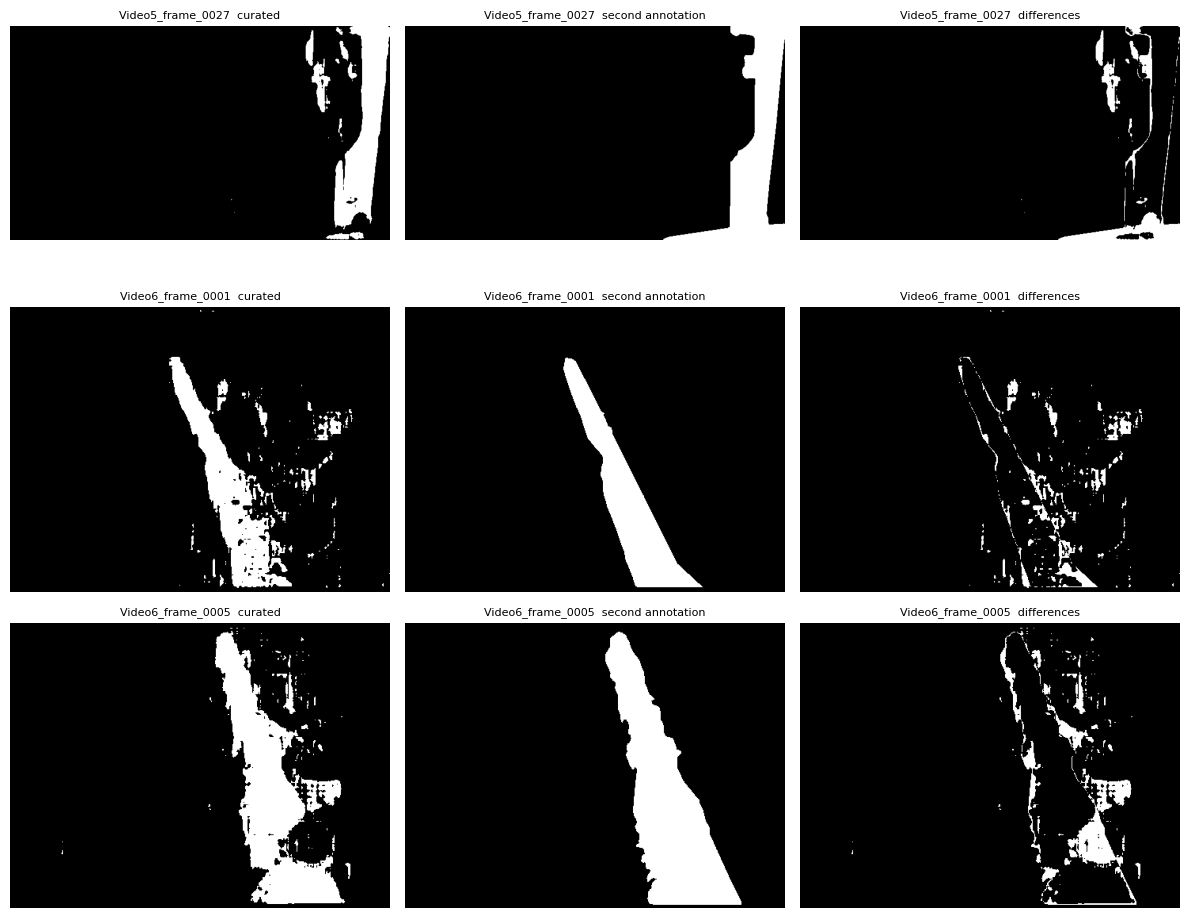

In [14]:
worst = df.nsmallest(3, "iou")["frame"].tolist()
fig, axes = plt.subplots(len(worst), 3, figsize=(12, 3.2 * len(worst)), squeeze=False)
for row, frame in zip(axes, worst):
    a, b = pairs[frame]
    for ax, img, title in zip(row, (a, b, a ^ b), ("curated", "second annotation", "differences")):
        ax.imshow(img, cmap="gray"); ax.set_title(f"{frame.removeprefix('DeepWater-')}  {title}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Save the tables to Drive

In [15]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(RESULTS_DIR / "concordancia_por_frame.csv", index=False)
per_video.round(4).to_csv(RESULTS_DIR / "concordancia_por_video.csv")
print("saved in", RESULTS_DIR)

saved in /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/Resultados_Concordancia
